In [1]:
from scipy import signal
import scipy
import os
import os.path as op
from functools import partial

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import hnn_core

from hnn_core import duecker_ET_model, simulate_dipole, read_dipole, average_dipoles, JoblibBackend, MPIBackend
from hnn_core.dipole import _rmse, _rmse_corr
from step2_optimize_ERP_cma import set_params_opt_drives
import numpy as np
from hnn_core import write_network_configuration, read_network_configuration
import pickle
from hnn_tuning.plot_utils import add_scalebar
hnn_core_root = op.join(op.dirname(hnn_core.__file__))
from step2_optimize_ERP_cma import rmse_corr_spike_times
from hnn_tuning import REPO_ROOT, NETWORK_SIM, results_dir
pth = str(REPO_ROOT)

import random

In [2]:
with open(f'opt_ERP_cma_100_sigma0_0.05.pkl', 'rb') as file:
        optim = pickle.load(file)

rng = random.Random(2026)

optim.net_._model_variant = "duecker_ET_model"                  # wasn't an attribute when network was tuned.
filename = op.join(str(NETWORK_SIM / 'ERP'), 'duecker_ET_supra_ERP.json')
write_network_configuration(optim.net_, filename)

net = read_network_configuration(filename)
net.set_cell_positions(inplane_distance=30.)
for cell_type in net.cell_types:
    net.pos_dict[cell_type] = [
        (x, y, z + rng.uniform(-200, 200))
        for x, y, z in net.pos_dict[cell_type]
    ]
depths = list(list(range(-500,2500,100)))
electrode_pos = [(135, 135, dep) for dep in depths]
net.add_electrode_array('probe1', electrode_pos)

/Users/katharinaduecker/Documents/projects_brown/hnn-core/hnn_core/network.py:933: FutureWarning: `Network.set_cell_positions` will be deprecated in favor of `Network.update_cell_positions` in future releases.
  warnings.warn(


In [3]:
tstop=175

with MPIBackend():
    dpl_opt = simulate_dipole(net, tstop=tstop, n_trials=40, dt=0.025, bsl_cor="duecker")

MPI will run 40 trial(s) sequentially by distributing network neurons over 11 processes.
numprocs=11
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/proje

In [4]:
dpl = [d.scale(1000) for d in dpl_opt]
dpl = [d.smooth(5) for d in dpl]
avg_dpl = average_dipoles(dpl)

In [11]:
pathgen = op.join(f'{pth}/data/hnn-data/')

data_url = f'{pathgen}MEG_detection_data/S1_SupraT.txt'
exp_dpl = read_dipole(data_url)

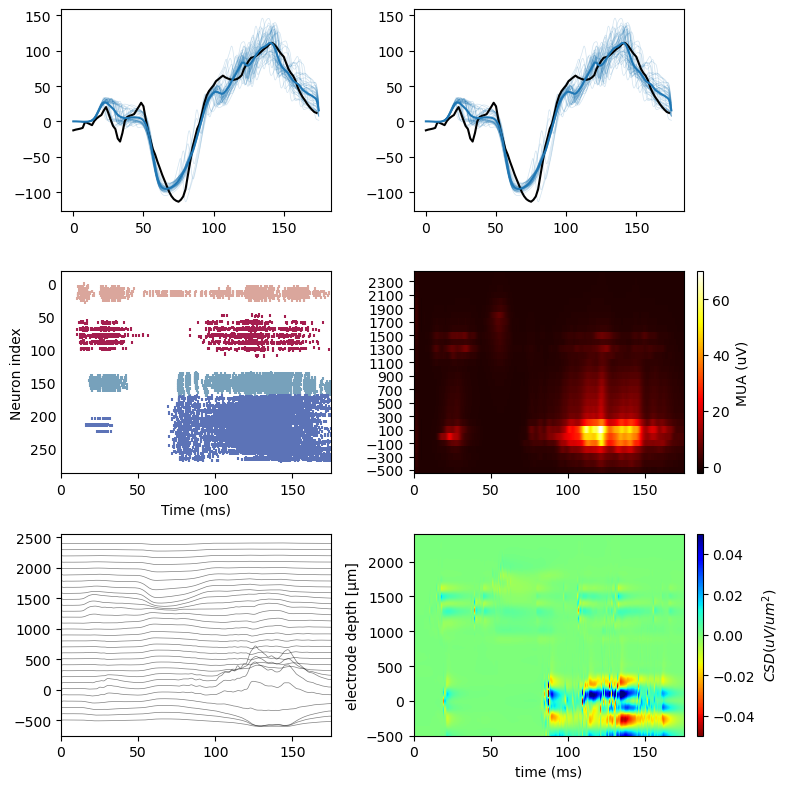

In [17]:
# Explore LFP, MUA, CSD
filtered_mua = np.zeros_like(net.rec_arrays["probe1"].voltages)
lfp = np.zeros_like(net.rec_arrays["probe1"].voltages)
N = 4
Wn = [300, 5_000]
fs = 1/(np.diff(net.rec_arrays["probe1"].times)[0]/1000)

sos_bp = signal.butter(N, Wn, btype='bp', analog=False, output='sos', fs=fs)
sos_lp = signal.butter(N, 300, btype='lp', analog=False, output='sos', fs=fs)

for er, extra_rec in enumerate(net.rec_arrays["probe1"].voltages):
    filtered_mua[er] = signal.sosfiltfilt(sos_bp, extra_rec,axis=1)
    lfp[er] = signal.sosfiltfilt(sos_lp, extra_rec)
lfp = lfp.mean(axis=0)
mua = np.abs(filtered_mua)
sos_lp = signal.butter(4, 200, btype='lowpass', output='sos', fs=fs)
muae = signal.sosfiltfilt(sos_lp, mua, axis=-1).mean(axis=0)


yticks = [net.rec_arrays["probe1"].positions[c][2] for c in range(len(muae))]

fig, ax = plt.subplots(3,2, figsize=(8,8), height_ratios=[1, 1, 1])

for i in range(2):
    for d in dpl:
        ax[0,i].plot(d.times, d.data["agg"], "tab:blue", alpha=0.2, linewidth=0.5)
    ax[0,i].plot(exp_dpl.times, exp_dpl.data["agg"], color="k")
    ax[0,i].plot(avg_dpl.times, avg_dpl.data["agg"], color="tab:blue")

# axtw = ax[1,0].twinx()
# for c, m in enumerate(muae):
#     axtw.plot(net.rec_arrays["probe1"].times, m+net.rec_arrays["probe1"].positions[c][2], color="k", alpha=0.5, linewidth=0.5)
# axtw.set_yticks(yticks[::2])
net.cell_response.plot_spikes_raster(ax=ax[1,0], show=False, show_legend=False)

im = ax[1,1].pcolormesh(net.rec_arrays["probe1"].times, yticks, muae, cmap="hot")
ax[1,1].set_yticks(yticks[::2])

color_axis = ax[1,1].inset_axes([1.05, 0, 0.02, 1], transform=ax[1,1].transAxes)
plt.colorbar(im, ax=ax, cax=color_axis).set_label(r"MUA (uV)")

for c, l in enumerate(lfp):
    ax[2,0].plot(net.rec_arrays["probe1"].times, l+net.rec_arrays["probe1"].positions[c][2], color="k", alpha=0.5, linewidth=0.5)
ax[2,0].set_xlim([0, 175])
net.rec_arrays["probe1"].plot_csd(ax=ax[2,1], show=False, interpolation="spline", sink="r", vmin=-0.05, vmax=0.05)

fig.tight_layout()

In [6]:
# Kulics and Cauller 1986
# P1 and P1a: superficial positive - check, deep-negative not check
# N1: surface negative
# P2: surface positive

# P1a most prominent in supragranular, while all other ones more prominent in deeper layers

# P1 shows polarity reversal from superficial to deep, mainly observed at the end of the post central gyrus
# N1 observable in more regions. It shows polarity reversal from superficial (top) to deep - we get the superficial down and an immediate reversal, not in the deep layers
# not all penetrations show combination of early and late MUA -> different columns involved?

In [7]:
nhp_lfp = scipy.io.loadmat('/Users/katharinaduecker/Documents/projects_brown/CONTE/soma_NHP/2-pb3738017_lfp.mat')
data = nhp_lfp['lfp']
data_csd = nhp_lfp['csd']
data_csd = data_csd - np.mean(data_csd[:,:200], axis=1, keepdims=True)
data_csd.shape

(21, 1100)

In [8]:
nhp_lfp

{'__header__': b'MATLAB 5.0 MAT-file, Platform: MACA64, Created on: Tue Feb 17 14:22:42 2026',
 '__version__': '1.0',
 '__globals__': [],
 'csd': array([[ 0.33789062,  0.70581055,  0.34716797, ...,  0.02172852,
         -0.48535156, -0.56762695],
        [-2.06738281, -2.20239258, -2.29296875, ..., -1.19213867,
         -1.37890625, -1.71850586],
        [ 1.35717773,  1.72338867,  2.14135742, ...,  2.40966797,
          2.97949219,  3.55200195],
        ...,
        [ 4.47094727,  4.61791992,  4.796875  , ...,  1.50048828,
          1.51611328,  1.31469727],
        [ 0.75952148,  0.60644531,  0.71533203, ..., -1.81518555,
         -1.96240234, -1.44750977],
        [-4.7878418 , -4.83520508, -5.08618164, ..., -4.79858398,
         -4.39501953, -5.07885742]], shape=(21, 1100)),
 'lfp': array([[ 12.53515625,  13.1472168 ,  14.09838867, ...,  53.62451172,
          53.46435547,  52.96679688],
        [ 12.53198242,  13.48168945,  14.19091797, ...,  53.67797852,
          53.08007812,  5

<>:13: SyntaxWarning: invalid escape sequence '\m'
<>:13: SyntaxWarning: invalid escape sequence '\m'
/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_24688/2837661696.py:13: SyntaxWarning: invalid escape sequence '\m'
  ax[1,0].set_ylabel('LFP $\mu$V')


Text(510.3244949494949, 0.5, 'contact')

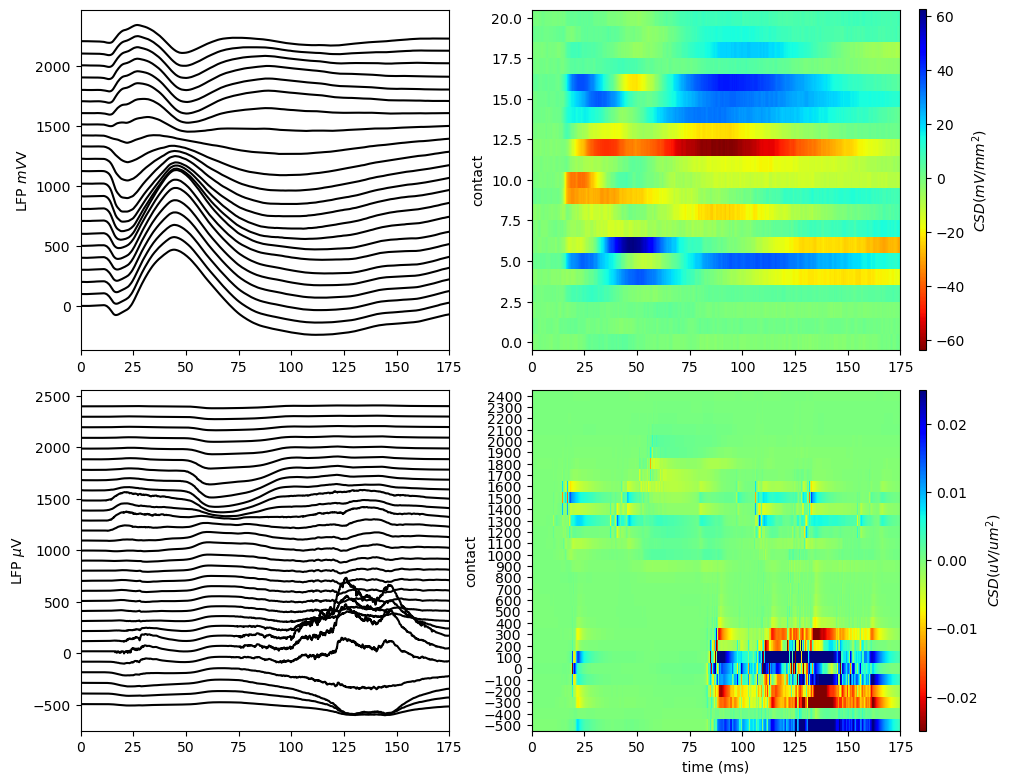

In [9]:



lfp_hnn = net.rec_arrays['probe1'].voltages.mean(axis=0)
cmap = plt.get_cmap('cool', lfp_hnn.shape[0])
colors = cmap(np.linspace(0, 1, lfp_hnn.shape[0]))


fig, ax = plt.subplots(2,2,figsize=(10,8))

for d, lfp in enumerate(lfp_hnn):
    ax[1,0].plot(dpl_opt[0].times, lfp+net.rec_arrays["probe1"].positions[d][2], color="k")
net.rec_arrays['probe1'].plot_csd(ax=ax[1,1], show=False, sink='r', colorbar=True, vmin=-0.025, vmax=0.025, interpolation=None)
ax[1, 1].set_ylabel('contact')
ax[1,1].set_yticks(yticks)
ax[1,0].set_ylabel('LFP $\mu$V')
ax[0,0].set_xlim([0, 175])
ax[1,0].set_xlim([0, 175])


for d, nlfp in enumerate(nhp_lfp['lfp']):
    ax[0,0].plot(nhp_lfp['timevec'].reshape(-1,)*1000-33, nlfp.reshape(-1,)+d*100, color="k")
ax[0,0].set_xlim([0, 175])
ax[0,0].set_ylabel('LFP $mV$V')


im = ax[0,1].pcolormesh(
        nhp_lfp['timevec'].reshape(-1,)*1000-33, np.arange(data_csd.shape[0]), data_csd, cmap='jet_r', shading="auto", rasterized=True)
color_axis = ax[0,1].inset_axes([1.05, 0, 0.02, 1], transform=ax[0,1].transAxes)
plt.colorbar(im, ax=ax, cax=color_axis).set_label(r"$CSD (mV/mm^{2})$")
ax[0,1].set_xlim([0, 175])
ax[0, 1].set_ylabel('contact')


In [10]:
nlfp.reshape(-1,)

array([-8.43994141, -7.57641602, -6.70678711, ...,  3.07519531,
        3.3034668 ,  3.60449219], shape=(1100,))